# 🚀 Entrenamiento YOLO11 para Dofus (Dataset v3)
Este notebook descarga tu dataset directamente desde Roboflow y entrena **YOLO11 Nano** usando la GPU gratuita de Google Colab (T4).

> **IMPORTANTE**: Asegúrate de ir a **Entorno de ejecución > Cambiar tipo de entorno de ejecución** y seleccionar **T4 GPU**.

In [2]:
# 1. Verificar GPU activa
!nvidia-smi

Tue Oct 20 05:40:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8             16W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
# 2. Instalar Ultralytics y Roboflow
!pip install -q ultralytics roboflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 52.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 37.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 139.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 11.2 MB/s eta 0:00:00


In [4]:
# 3. Descargar el Dataset de Dofus (Versión 3)
from roboflow import Roboflow

rf = Roboflow(api_key="N7AVOoYW1Ic6G3ZVOLQW")
project = rf.workspace("nolger-rodriguez").project("dofus-orfkf")
version = project.version(3)
dataset = version.download("yolov8")

print(f"\nDataset descargado en: {dataset.location}")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to dofus-3 in yolov8:: 100%|██████████| 420/420 [00:00<00:00, 3001.08it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.

Dataset descargado en: /content/dofus-3


In [5]:
# 4. Entrenar YOLO11 Nano en GPU (50 épocas ~ 1 a 2 minutos)
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

results = model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=50,
    imgsz=512,
    batch=16,
    device=0,
    name="dofus_v3",
    project="runs/detect"
)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dofus-3/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=dofus_v3, nbs=64, nms=None, opset=None, optimize=False, optimi

In [14]:
# 4b. Entrenamiento Optimizado para mejorar resultados
from ultralytics import YOLO

# Usamos el modelo 'Small' (yolo11s.pt) que tiene más capacidad que el 'Nano'
model_optimized = YOLO("yolo11s.pt")

results_optimized = model_optimized.train(
    data=f"{dataset.location}/data.yaml",
    epochs=100,             # Más épocas para asegurar convergencia
    imgsz=640,              # Resolución nativa de YOLO para mejor detección de detalles pequeños
    batch=16,
    device=0,
    patience=20,            # Detiene el entrenamiento si no mejora en 20 épocas
    lr0=0.01,               # Tasa de aprendizaje inicial estándar
    lrf=0.01,
    box=7.5,                # Peso de la pérdida de caja
    cls=1.0,                # Aumentamos el peso de la pérdida de clase para reducir falsos negativos
    hsv_h=0.015,            # Variaciones de tono leves
    hsv_s=0.4,              # Variaciones de saturación
    hsv_v=0.3,              # Variaciones de brillo (útil para diferentes zonas del juego)
    degrees=0.0,            # No rotamos porque la perspectiva en Dofus es fija
    fliplr=0.5,             # Espejado horizontal permitido
    name="dofus_v3_optimized",
    project="runs/detect"
)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=1.0, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dofus-3/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=dofus_v3_optimized, nbs=64, nms=None, opset=None, optimize=Fa

### ¿Cómo evaluar este nuevo entrenamiento?
Una vez termine la ejecución de la celda superior, puedes visualizar y descargar el nuevo mejor modelo (`dofus_v3_optimized`) usando las mismas celdas de abajo, simplemente cambiando la variable `base_path` a:
`runs/detect/runs/detect/dofus_v3_optimized`

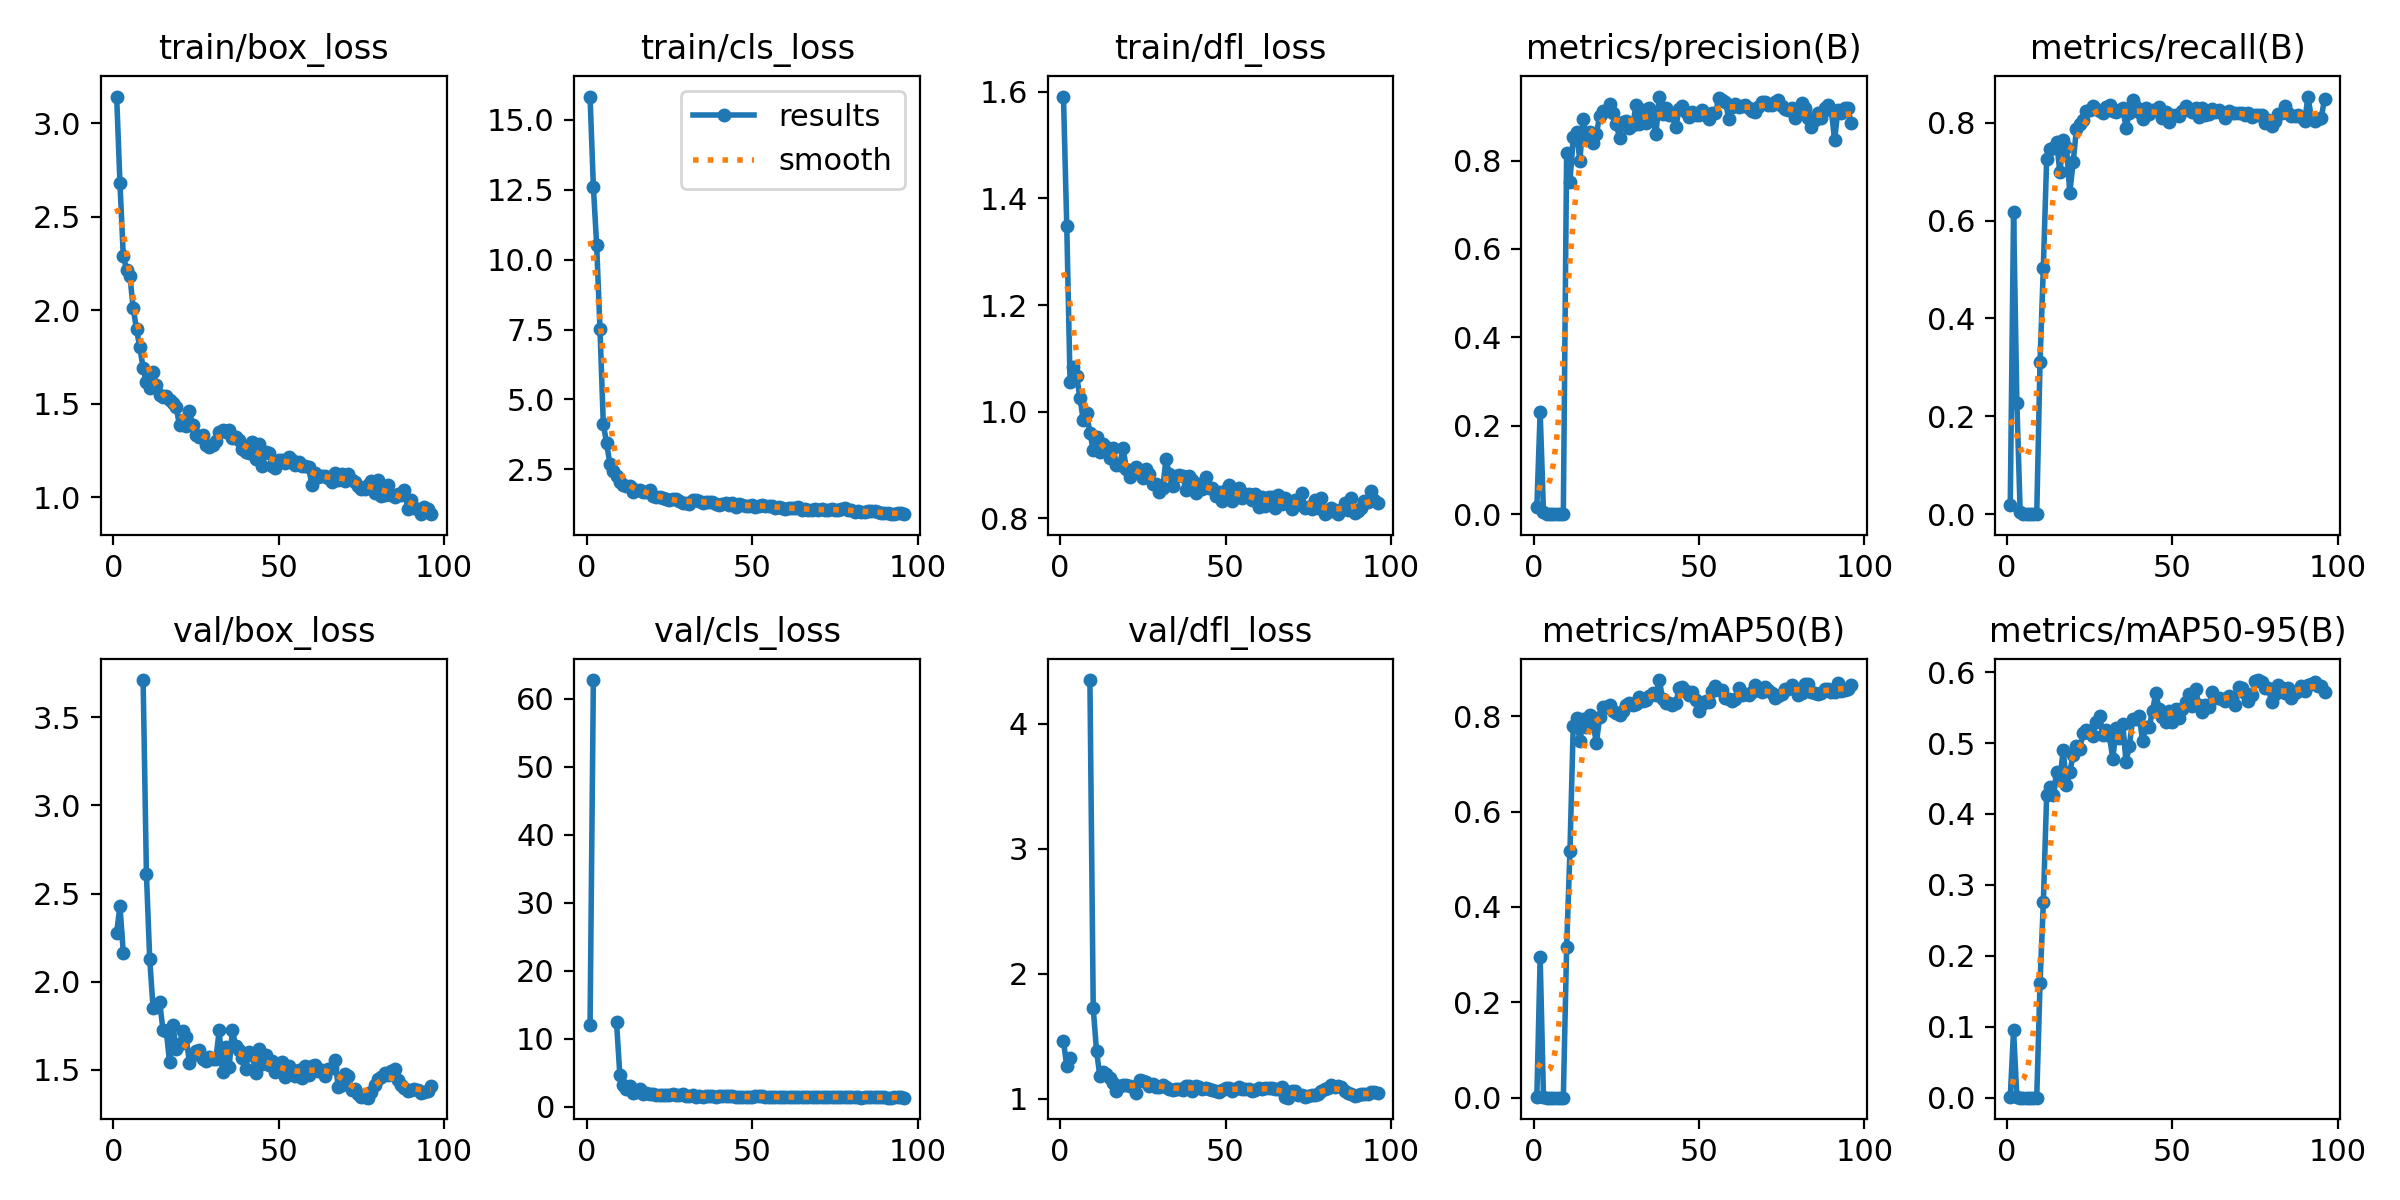

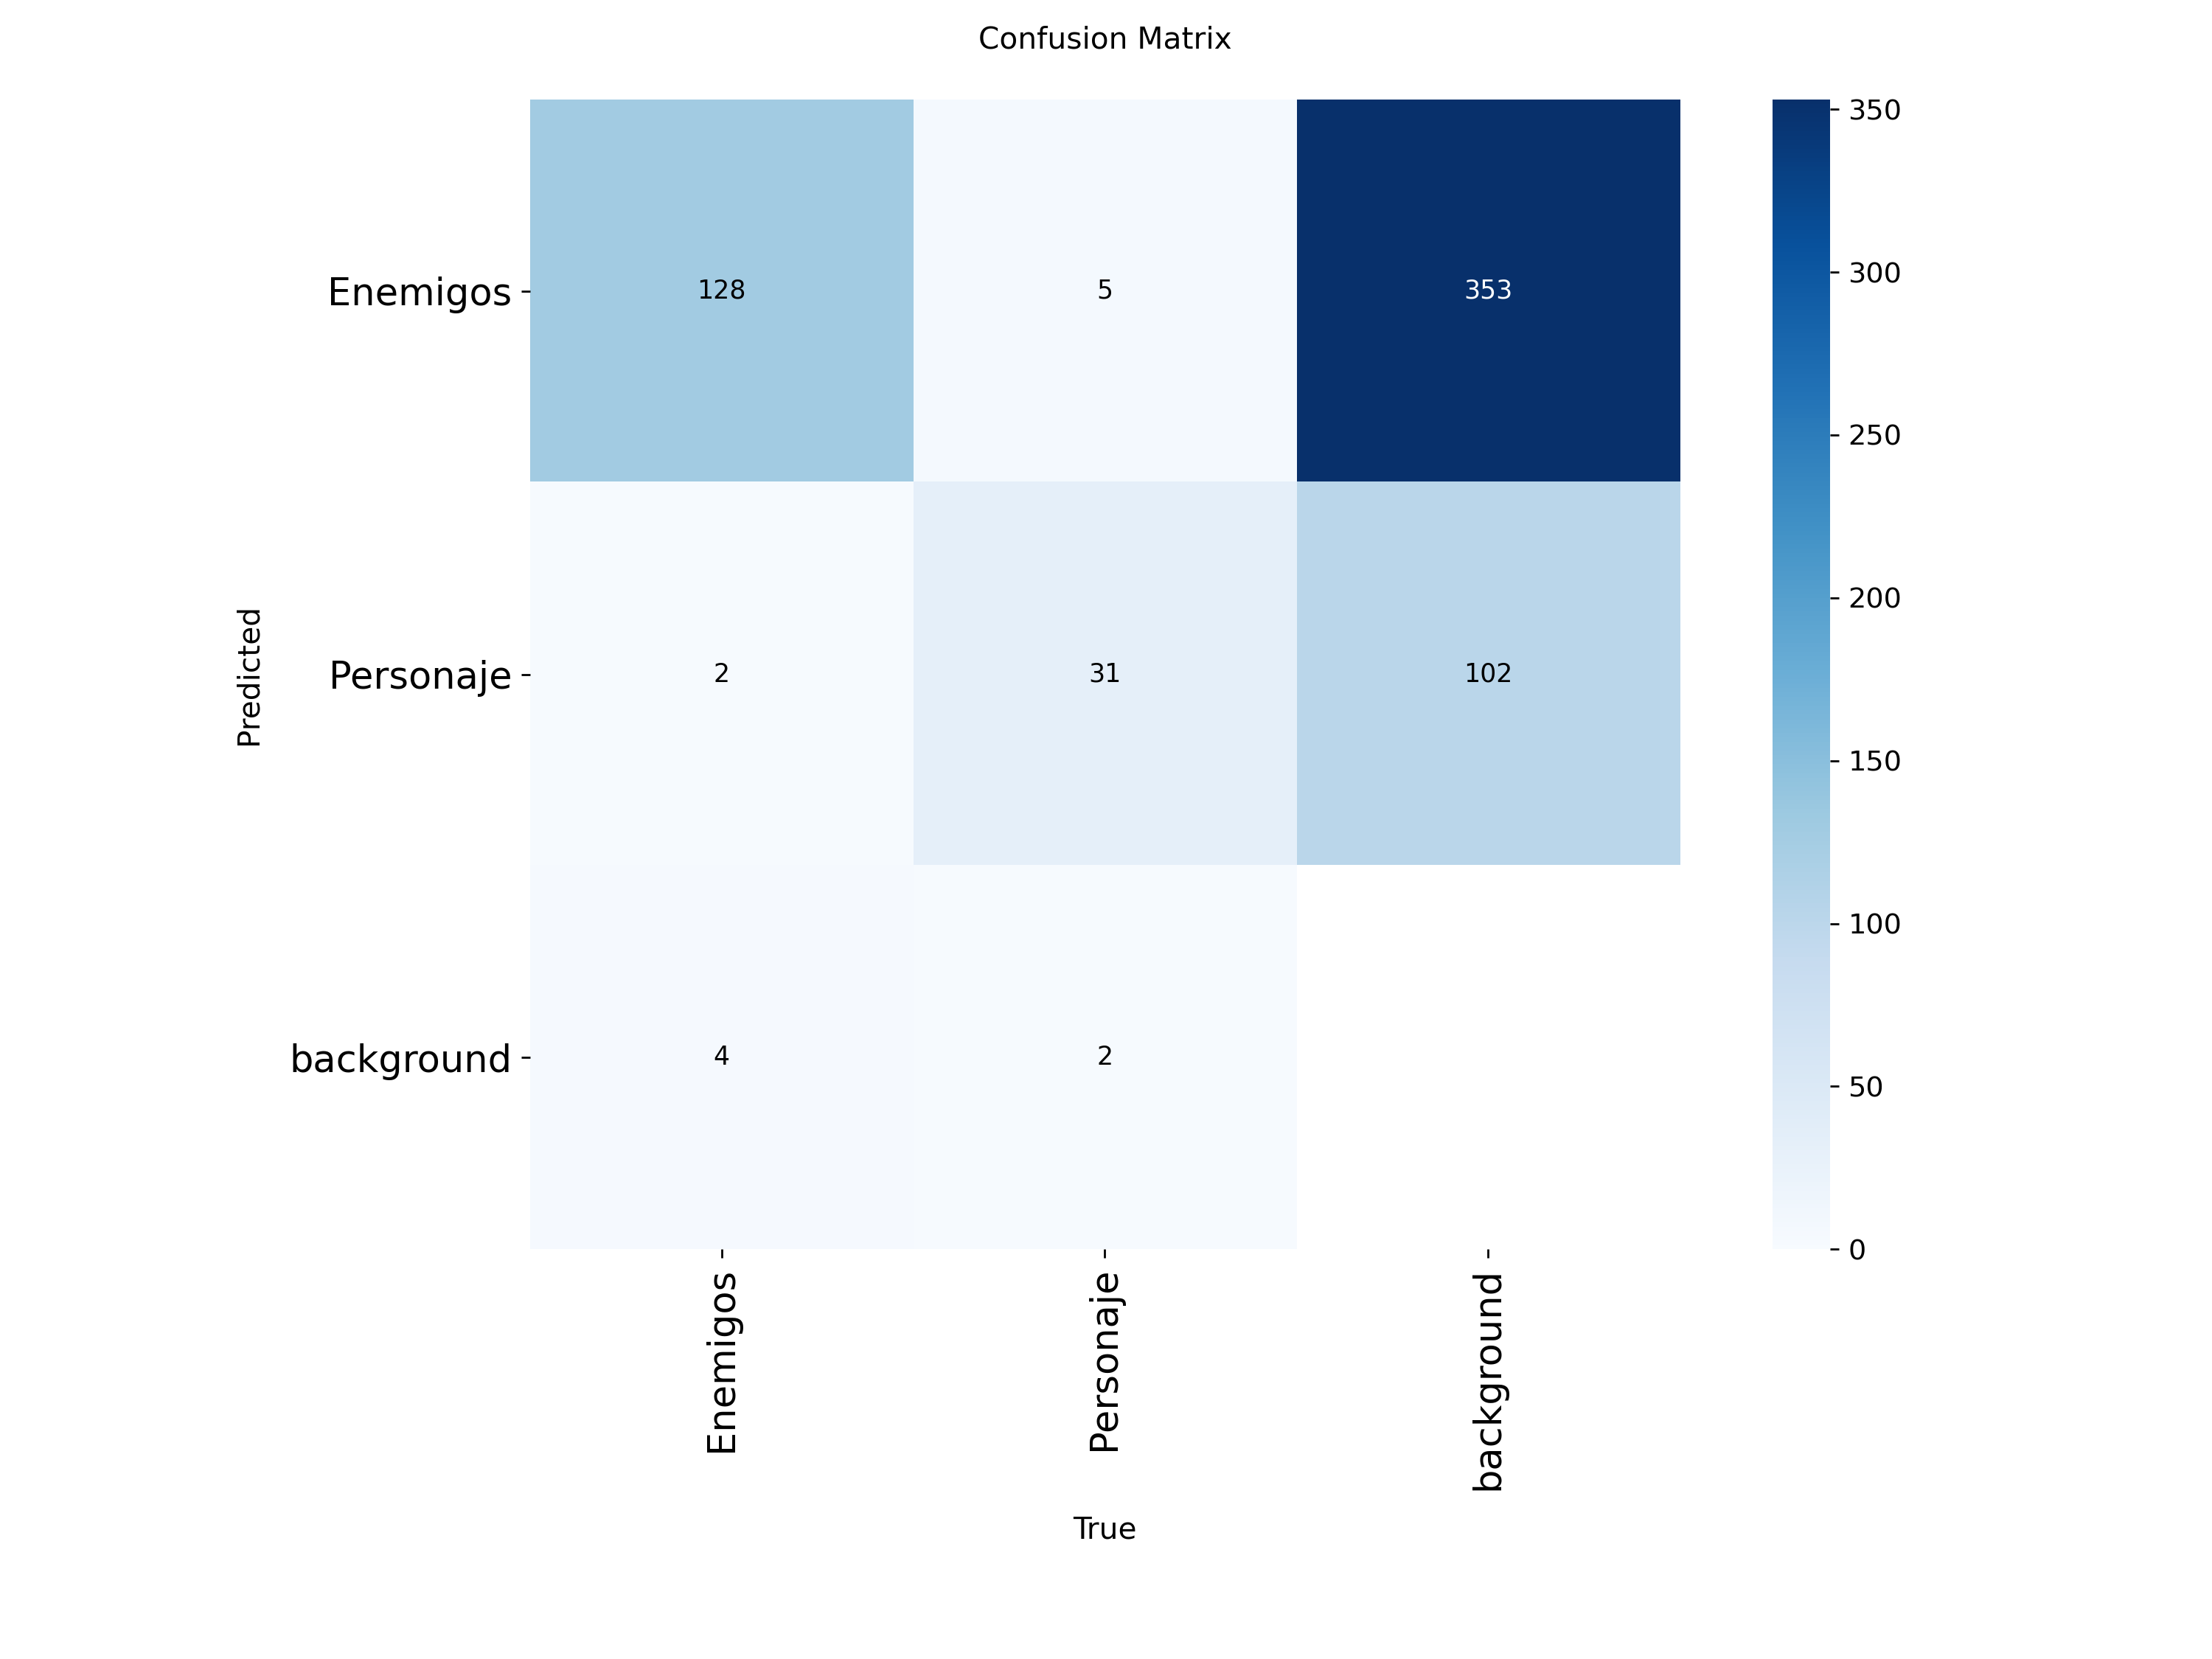

In [15]:
# 5. Ver métricas y gráficas del entrenamiento (Optimizado)
from IPython.display import Image, display
import os

# Apuntamos al directorio del entrenamiento optimizado
base_path = "runs/detect/runs/detect/dofus_v3_optimized"

results_img = os.path.join(base_path, "results.png")
if os.path.exists(results_img):
    display(Image(filename=results_img))
else:
    print(f"No se encontró {results_img}")

confusion_matrix = os.path.join(base_path, "confusion_matrix.png")
if os.path.exists(confusion_matrix):
    display(Image(filename=confusion_matrix))
else:
    print(f"No se encontró {confusion_matrix}")

In [16]:
# 6. Descargar el modelo entrenado optimizado (best.pt) a tu computadora
from google.colab import files
import os

# Apuntamos al directorio del entrenamiento optimizado
base_path = "runs/detect/runs/detect/dofus_v3_optimized"
best_weights = os.path.join(base_path, "weights/best.pt")

if os.path.exists(best_weights):
    print("Descargando best.pt optimizado...")
    files.download(best_weights)
else:
    print(f"No se encontró el archivo de pesos en: {best_weights}")

Descargando best.pt optimizado...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>